<div style="width:100%; background-color:#181818; color:#f1f1f1; padding:30px 0; text-align:center; border-radius:10px;">
  <img src="https://media3.giphy.com/media/v1.Y2lkPTc5MGI3NjExeGZqamQ3dWQ2YWM4aW50OHZjdzRpN29sdWVhbnByYndpYzIyZW5jayZlcD12MV9pbnRlcm5hbF9naWZfYnlfaWQmY3Q9Zw/xT3i1ei3Ui7rpgrsyc/giphy.gif" alt="Reinforced concrete design animation" width="400" style="max-width:100%; border-radius:10px;">
  <h3 style="color:#ffffff; margin:0 0 8px 0;"><b>Column, Interaction Diagram</b></h3>
  <p style="margin:4px 0;"><b>Authors:</b> Msc. Ing. Carlos Andr&eacute;s Celi S&aacute;nchez &middot; Nicol&aacute;s Mora Bowen &middot; Juan Sebasti&aacute;n Baquero</p>
  <p style="margin:4px 0;"><b>Course:</b> Reinforced Concrete Design II</p>
</div>

### Libraries

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### Data

In [18]:
h = 50
b = 30
fc = 280
fy = 4200
Es = 2000000
ecu = 0.003
beta1 = 0.85

dd = np.array([6.10, 25, 43.90])
dvar = np.array([2.2,2.2,2.2])
numvar = np.array([3,0,3])

### Calculation

In [19]:
ety = fy / Es
bwit = 0.85*fc

asi = np.pi * dvar**(2) / 4 * numvar 
Ag = b*h
Ast = np.sum(asi)
ratio  = Ast / Ag

yr = h/2
brp = np.abs(yr - dd)

cond = 0.1*Ag*fc

Po = 0.85*(fc*(Ag - Ast)) + fy*Ast
print(Po)
Pno = 0.8*(Po)
Mno = 0

if ratio >= 0.01:

    PN = []
    MN = []

    for cc in np.arange(h*1.1,0,-0.1):
        #-------Compresion controled------#
        c = cc
        a = beta1*c

        #--Stress and Strain Steel--#
        esi = []
        fsi = []
        for i in np.arange(0,len(dd),1):
            esi.append(np.abs(ecu*(dd[i]-c)/c))
            if esi[i] <= ety:
                fsi.append(Es*esi[i])
            else:
                fsi.append(fy)

        #--Internal Forces / Steel--#
        Csi = []
        for i in np.arange(0,len(dd),1):
            if dd[i] <= a:
                Csi.append(asi[i]*(fsi[i] - bwit))
            else:
                Csi.append(asi[i]*fsi[i] * -1)
        Cc = bwit*a*b

        Pn = Cc + np.sum(Csi)

        #--Moments--#
        Mn = Cc*(yr - a/2) + np.sum(Csi * (yr - dd))
        

        PN.append(Pn / 1000)
        MN.append(Mn / 1e5)

        # print('='*120)
        # print('.'*90)
        # print('Geometry')
        # print(f'b = {b:.2f} cm , h = {h:.2f} cm')
        # print(f'Plastic Centroid = {yr:.2f} cm')
        # print(f'Neutral Axis = {c:.2f} cm')
        # print(f'a = {a:.2f} cm')
        # print(f'ds = {dd} cm')
        # print('.'*90)
        # print('Areas Materials')
        # print(f'As_i = {asi} cm2')
        # print(f'Ag = {Ag:.2f} cm2')
        # print('.'*90)
        # print('Strain Materials')
        # print(f'ety = {ety:.6f}')
        # print(f'es_i = {esi}')
        # print('.'*90)
        # print('Stess Materials')
        # print(f'fs_i = {fsi} kg/cm2')
        # print(f'0.85fc = {bwit:.2f} kg/cm2')
        # print('.'*90)
        # print('Force Materials')
        # print(f'Cs_i = {Csi} kg')
        # print(f'Cc = {Cc} kg')

        # print('.'*90)
        # print('Internal Capacity')
        # print(f'Pn = {Pn / 1000:.2f} T')
        # print(f'Mn = {Mn / 1e5:.2f} T-m')
        # print('='*120)

    print(PN)
    print(MN)
else:
    mensaje = {'error'}

447365.1480789752
[390.07261115046464, 389.3662308165356, 388.6594874156943, 387.9523789567147, 387.2449034337827, 386.53705882636297, 385.8288430990631, 385.12025420149683, 384.4112900681462, 383.70194861822125, 382.99222775551874, 382.2821253682795, 381.5716393290429, 380.8607674945019, 380.1495077053545, 379.4378577861542, 378.72581554515904, 378.01337877417905, 377.30054524842086, 376.5873127263321, 375.87367894944305, 375.1596416422066, 374.44519851183657, 373.7303472481446, 373.0150855233739, 372.29941099203256, 371.58332129072437, 370.8668140379772, 370.1498868340699, 369.43253726085794, 368.71476288159505, 367.99656124075506, 367.2779298638502, 366.55886625724725, 348.13243261384923, 347.63856823825614, 347.1451436899953, 346.65216154115654, 346.1596243839238, 345.6675348307723, 345.17589551466745, 344.6847090892654, 344.19397822911765, 343.7037056298767, 343.21389400850427, 342.72454610348285, 342.2356646750289, 341.7472525053086, 341.2593123986572, 340.77184718179967, 340.284

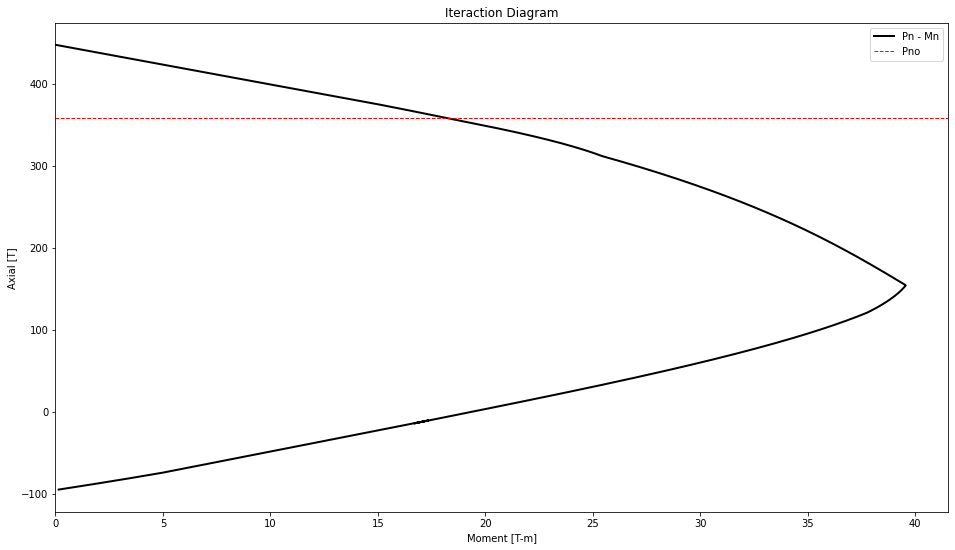

In [20]:
PNN = np.insert(PN,0,Po/1000)
MNN = np.insert(MN,0,Mno/1e5)

fig, ax = plt.subplots(1,1, figsize = (16,9))
ax.plot(MNN,PNN, ls = '-', lw = 2, color = [0,0,0], label = 'Pn - Mn')
ax.axhline(Pno/1000, ls = '--', lw = 1, color = [1,0,0], label = 'Pno')
ax.set_title('Iteraction Diagram')
ax.set_xlabel('Moment [T-m]')
ax.set_ylabel('Axial [T]')
ax.set_xlim(0,np.max(MN)*1.05)
ax.legend()

In [21]:
PN_df = pd.DataFrame(PNN)
PN_df

,0
0,447.365148
1,390.072611
2,389.366231
3,388.659487
4,387.952379
...,...
546,-92.758943
547,-93.365843
548,-93.972743
549,-94.579643
